In [3]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns

# 1.Rutas y lectura de archivos

In [4]:
BASE_DIR = Path.cwd().resolve().parent
BASE_DIR

ruta_crudos = BASE_DIR / "data" / "raw" / "2025"
ruta_procesados = BASE_DIR / "data" / "procesado"

departamentos = ["LIMA", "ICA", "AREQUIPA", "JUNIN", "SAN MARTIN"]

ruta_mapa_departamentos = BASE_DIR / "data" / "geo" / "LIM_DEPARTAMENTAL_PERU_MIN.json"
ruta_mapa_provincias = BASE_DIR / "data" / "geo" / "LIM_PROVINCIAL_PERU_MIN.json"

df_01_CARATULA = pd.read_parquet(ruta_crudos / "01_CARATULA.parquet")
df_03_CAP200A = pd.read_parquet(ruta_crudos / "03_CAP200A.parquet")

# 2.Limpieza de archivos

In [5]:
df_03_CAP200A_limp = df_03_CAP200A.copy()

df_03_CAP200A_limp["NOMBREDD"] = df_03_CAP200A_limp["NOMBREDD"].str.strip().str.upper()
df_03_CAP200A_limp["NOMBREPV"] = df_03_CAP200A_limp["NOMBREPV"].str.strip().str.upper()

df_03_CAP200A_limp = df_03_CAP200A_limp[df_03_CAP200A_limp["NOMBREDD"].isin(departamentos)].copy()


print("Registros originales:", len(df_03_CAP200A))
print("Registros filtrados:", len(df_03_CAP200A_limp))

df_03_CAP200A_limp["NOMBREDD"].value_counts()

Registros originales: 118589
Registros filtrados: 21523


NOMBREDD
AREQUIPA      10041
LIMA           5316
JUNIN          3274
SAN MARTIN     1857
ICA            1035
Name: count, dtype: int64

# 3.Mapas

In [6]:
mapa_departamentos = gpd.read_file(ruta_mapa_departamentos)
mapa_provincias = gpd.read_file(ruta_mapa_provincias)

mapa_departamentos["NOMBDEP"] = mapa_departamentos["NOMBDEP"].str.strip().str.upper()
mapa_provincias["NOMBDEP"] = mapa_provincias["NOMBDEP"].str.strip().str.upper()
mapa_provincias["NOMBPROV"] = mapa_provincias["NOMBPROV"].str.strip().str.upper()

mapa_departamentos = mapa_departamentos[mapa_departamentos["NOMBDEP"].isin(departamentos)].copy()
mapa_provincias = mapa_provincias[mapa_provincias["NOMBDEP"].isin(departamentos)].copy()

mapa_provincias["NOMBPROV"] = mapa_provincias["NOMBPROV"].replace("CAÃ‘ETE", "CANIETE")
df_03_CAP200A_limp["NOMBREPV"] = df_03_CAP200A_limp["NOMBREPV"].replace("CAÃ‘ETE", "CANIETE")

print("Departamentos:", mapa_departamentos["NOMBDEP"].unique())
print("Provincias:", len(mapa_provincias))

Departamentos: <ArrowStringArray>
['AREQUIPA', 'ICA', 'JUNIN', 'LIMA', 'SAN MARTIN']
Length: 5, dtype: str
Provincias: 42


## Gráfico 1. Diversidad de cultivos por provincia

In [7]:
# Tabla estadística
tabla_01 = df_03_CAP200A_limp.groupby(["NOMBREDD", "NOMBREPV"])["P204_COD"].nunique().reset_index(name="cantidad_cultivos")
tabla_01

,NOMBREDD,NOMBREPV,cantidad_cultivos
0,AREQUIPA,AREQUIPA,4
1,AREQUIPA,CAMANA,1
2,AREQUIPA,CARAVELI,1
3,AREQUIPA,CASTILLA,5
4,AREQUIPA,CAYLLOMA,6
5,AREQUIPA,CONDESUYOS,6
6,AREQUIPA,ISLAY,1
7,AREQUIPA,LA UNION,5
8,ICA,CHINCHA,3
9,ICA,ICA,1


In [8]:
# Merge
mapa_01 = mapa_provincias.merge(
    tabla_01,
    left_on=["NOMBDEP", "NOMBPROV"],
    right_on=["NOMBREDD", "NOMBREPV"],
    how="left"
).copy()

print("Provincias con datos:", mapa_01["cantidad_cultivos"].notna().sum())

Provincias con datos: 41


In [9]:
mapa_01.loc[mapa_01['NOMBREPV']=='CANIETE']

,OBJECTID_1,OBJECTID,CCDD,NOMBDEP,CCPP,NOMBPROV,CAPITAL,IDPROV,Shape_STAr,Shape_STLe,ORIG_FID,Shape_Leng,Shape_Area,geometry,NOMBREDD,NOMBREPV,cantidad_cultivos


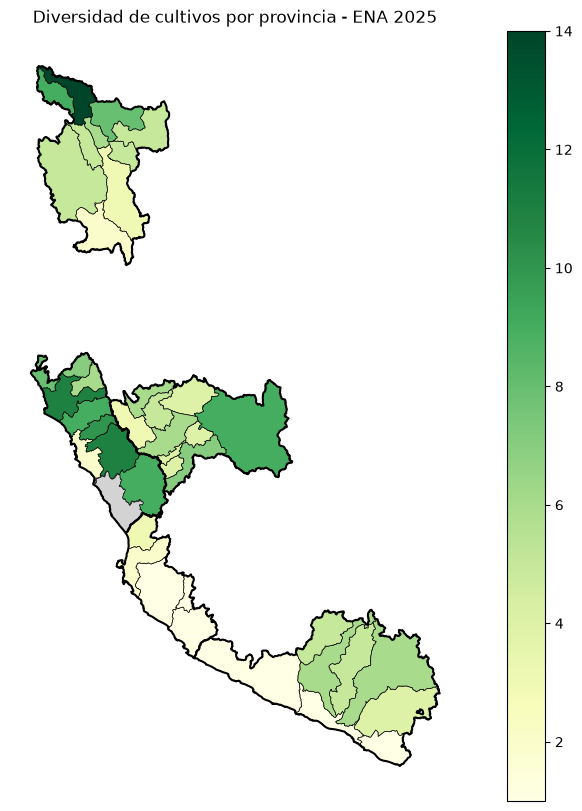

In [10]:
# Mapa coroplético

fig, ax = plt.subplots(figsize=(12, 10))
mapa_01.plot(
    column="cantidad_cultivos",
    cmap="YlGn",
    legend=True,
    edgecolor="black",
    linewidth=0.5,
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    ax=ax
)

mapa_departamentos.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5
)

ax.set_title("Diversidad de cultivos por provincia - ENA 2025")
ax.set_axis_off()
plt.show()

## Gráfico 2. Cantidad de unidades agropecuarias por provincia

In [11]:
# Tabla estadística
columnas_ua = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "ID_PROD", "UA"]

df_ua = df_03_CAP200A_limp.dropna(subset=columnas_ua).drop_duplicates(subset=columnas_ua).copy()
tabla_02 = df_ua.groupby(["NOMBREDD", "NOMBREPV"]).size().reset_index(name="cantidad_ua")
tabla_02

,NOMBREDD,NOMBREPV,cantidad_ua
0,AREQUIPA,AREQUIPA,228
1,AREQUIPA,CAMANA,6
2,AREQUIPA,CARAVELI,57
3,AREQUIPA,CASTILLA,175
4,AREQUIPA,CAYLLOMA,305
5,AREQUIPA,CONDESUYOS,138
6,AREQUIPA,ISLAY,49
7,AREQUIPA,LA UNION,140
8,ICA,CHINCHA,14
9,ICA,ICA,12


In [12]:
# Merge geográfico
mapa_02 = mapa_provincias.merge(
    tabla_02,
    left_on=["NOMBDEP", "NOMBPROV"],
    right_on=["NOMBREDD", "NOMBREPV"],
    how="left"
).copy()

print("Provincias con datos:", mapa_02["cantidad_ua"].notna().sum())

Provincias con datos: 41


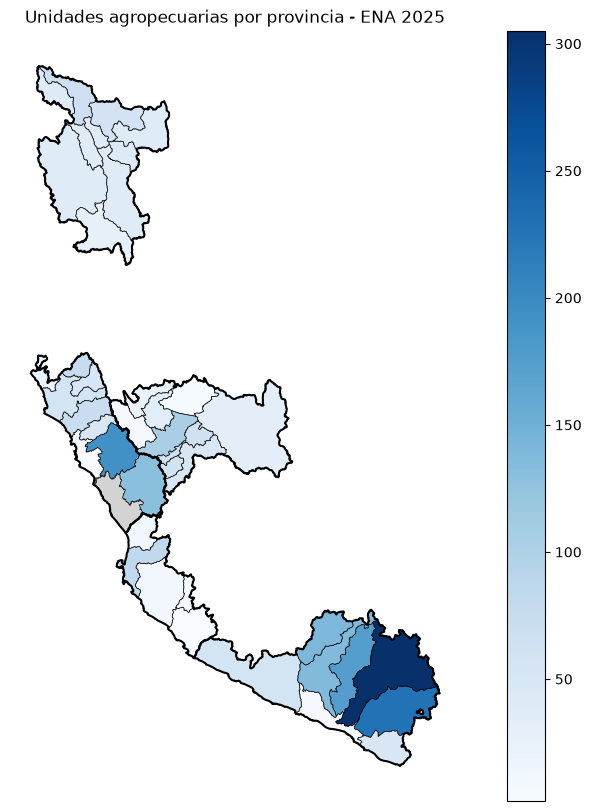

In [13]:
# Mapa coroplético

fig, ax = plt.subplots(figsize=(12, 10))
mapa_02.plot(
    column="cantidad_ua",
    cmap="Blues",
    legend=True,
    edgecolor="black",
    linewidth=0.5,
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    ax=ax
)

mapa_departamentos.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5
)

ax.set_title("Unidades agropecuarias por provincia - ENA 2025")
ax.set_axis_off()
plt.show()

## Gráfico 3. Cultivo más frecuente por provincia

In [14]:
# Tabla estadística
tabla_03 = df_03_CAP200A_limp.groupby(["NOMBREDD", "NOMBREPV", "P204_NOM"]).size().reset_index(name="cantidad")

tabla_03 = tabla_03.sort_values(["cantidad", "P204_NOM"], ascending=[False, True])
tabla_03 = tabla_03.drop_duplicates(subset=["NOMBREDD", "NOMBREPV"])
tabla_03

,NOMBREDD,NOMBREPV,P204_NOM,cantidad
11,AREQUIPA,CAYLLOMA,ALFALFA,2436
0,AREQUIPA,AREQUIPA,ALFALFA,2262
6,AREQUIPA,CASTILLA,ALFALFA,1668
17,AREQUIPA,CONDESUYOS,ALFALFA,1095
24,AREQUIPA,LA UNION,ALFALFA,974
124,LIMA,HUAROCHIRI,ALFALFA,899
35,ICA,PISCO,ALFALFA,777
154,LIMA,YAUYOS,ALFALFA,527
23,AREQUIPA,ISLAY,ALFALFA,516
5,AREQUIPA,CARAVELI,ALFALFA,513


In [15]:
# Merge geográfico
mapa_03 = mapa_provincias.merge(
    tabla_03,
    left_on=["NOMBDEP", "NOMBPROV"],
    right_on=["NOMBREDD", "NOMBREPV"],how="left"
).copy()

print("Provincias con datos:", mapa_03["cantidad"].notna().sum())

Provincias con datos: 41


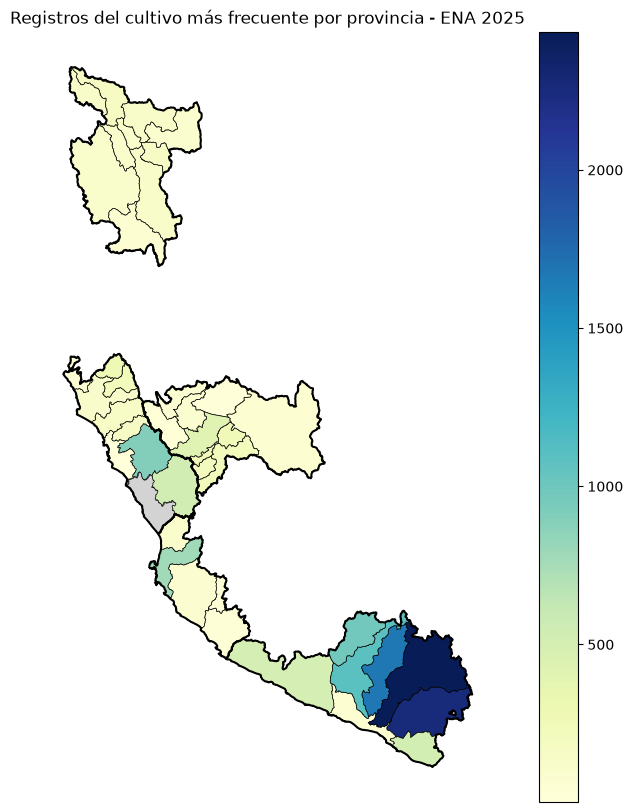

In [16]:
# Mapa coroplético

fig, ax = plt.subplots(figsize=(12, 10))
mapa_03.plot(
    column="cantidad",
    cmap="YlGnBu",
    legend=True,
    edgecolor="black",
    linewidth=0.5,
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    ax=ax
)

mapa_departamentos.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5
)

ax.set_title("Registros del cultivo más frecuente por provincia - ENA 2025")
ax.set_axis_off()
plt.show()

## Gráfico 4. Diversidad de cultivos por provincias de Lima

In [17]:
# Tabla estadística

df_lima = df_03_CAP200A_limp[df_03_CAP200A_limp["NOMBREDD"] == "LIMA"].copy()
tabla_04 = df_lima.groupby("NOMBREPV")["P204_COD"].nunique().reset_index(name="cantidad_cultivos")
tabla_04

,NOMBREPV,cantidad_cultivos
0,BARRANCA,8
1,CAJATAMBO,7
2,CANIETE,5
3,CANTA,10
4,HUARAL,9
5,HUAROCHIRI,11
6,HUAURA,11
7,LIMA,2
8,OYON,6
9,YAUYOS,9


In [18]:
# Merge geográfico

provincias_lima = mapa_provincias[mapa_provincias["NOMBDEP"] == "LIMA"].copy()

mapa_04 = provincias_lima.merge(
    tabla_04, 
    left_on="NOMBPROV", 
    right_on="NOMBREPV", 
    how="left"
).copy()

print("Provincias con datos:", mapa_04["cantidad_cultivos"].notna().sum())

Provincias con datos: 9


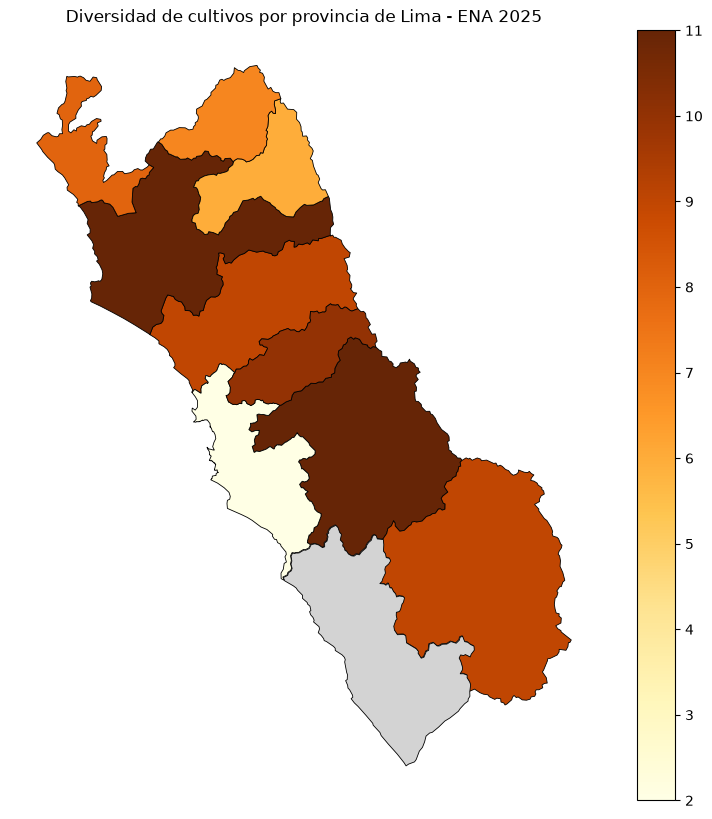

In [19]:
# Mapa coroplético

fig, ax = plt.subplots(figsize=(10, 10))
mapa_04.plot(
    column="cantidad_cultivos",
    cmap="YlOrBr", 
    legend=True, 
    edgecolor="black", 
    linewidth=0.6, 
    missing_kwds={"color": "lightgrey", "label": "Sin datos"}, 
    ax=ax)

ax.set_title("Diversidad de cultivos por provincia de Lima - ENA 2025")
ax.set_axis_off()
plt.show()

## Gráfico 5. Los 10 cultivos más registrados

In [20]:
# Tabla estadística

tabla_05 = df_03_CAP200A_limp["P204_NOM"].value_counts().head(10).sort_values()
tabla_05

P204_NOM
PASTO KING GRASS             81
PASTO ELEFANTE              239
PASTO NATURAL MANEJADO      495
PASTO BRAQUIARIA            541
PASTO DACTYLIS              669
TREBOL                      791
PASTO BRIZANTA             1068
PASTO KIKUYO               1302
RYE GRASS                  1923
ALFALFA                   13856
Name: count, dtype: int64

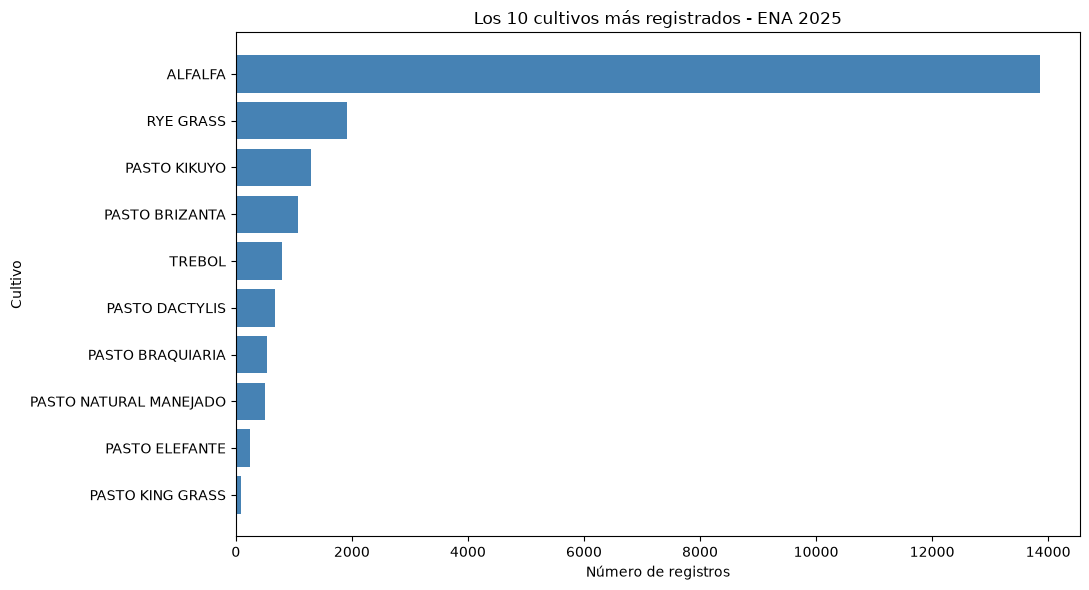

In [21]:
# Gráfico de barras horizontales

plt.figure(figsize=(11, 6))

plt.barh(
    tabla_05.index, 
    tabla_05.values, 
    color="steelblue")

plt.title("Los 10 cultivos más registrados - ENA 2025")
plt.xlabel("Número de registros")
plt.ylabel("Cultivo")
plt.tight_layout()
plt.show()

## Gráfico 6. Cantidad de cultivos distintos por departamento

In [22]:
# Tabla estadística

tabla_06 = df_03_CAP200A_limp.groupby("NOMBREDD")["P204_COD"].nunique().reset_index(name="cantidad_cultivos")
tabla_06

,NOMBREDD,cantidad_cultivos
0,AREQUIPA,12
1,ICA,4
2,JUNIN,13
3,LIMA,24
4,SAN MARTIN,21


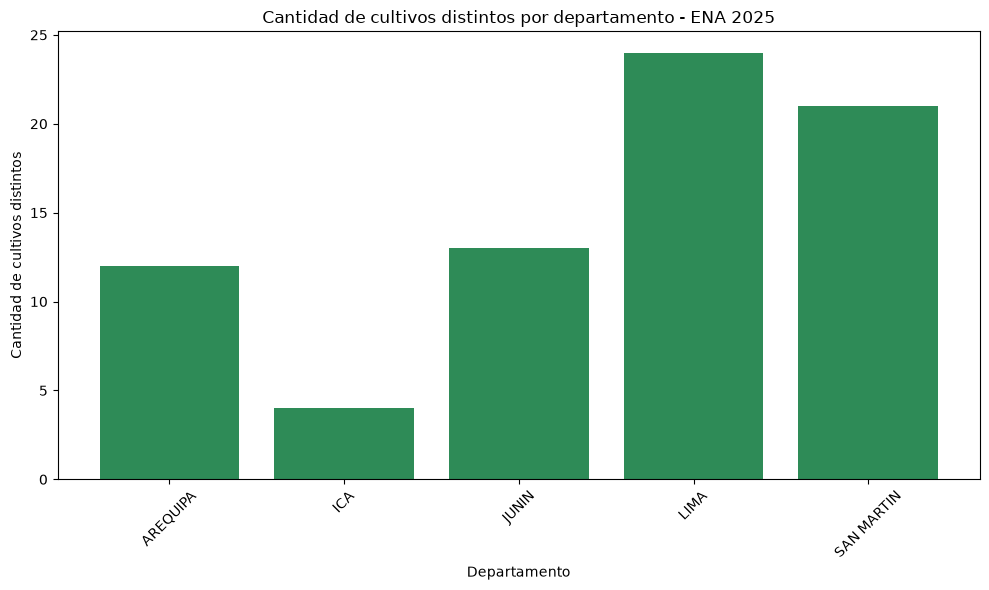

In [23]:
# Gráfico de barras

plt.figure(figsize=(10, 6))

plt.bar(
    tabla_06["NOMBREDD"],
    tabla_06["cantidad_cultivos"], 
    color="seagreen")

plt.title("Cantidad de cultivos distintos por departamento - ENA 2025")
plt.xlabel("Departamento")
plt.ylabel("Cantidad de cultivos distintos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Gráfico 7. Porcentaje de UA con más de un cultivo por departamento

In [24]:
# Tabla estadística

columnas_ua = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "ID_PROD", "UA"]

df_ua = df_03_CAP200A_limp.dropna(subset=columnas_ua).copy()

tabla_ua = df_ua.groupby(columnas_ua + ["NOMBREDD"])["P204_COD"].nunique().reset_index(name="cultivos_distintos")
tabla_ua["varios_cultivos"] = (tabla_ua["cultivos_distintos"] > 1).astype(int)

tabla_07 = tabla_ua.groupby("NOMBREDD")["varios_cultivos"].mean().reset_index(name="porcentaje")
tabla_07["porcentaje"] = (tabla_07["porcentaje"] * 100).round(2)

tabla_07

,NOMBREDD,porcentaje
0,AREQUIPA,5.37
1,ICA,2.59
2,JUNIN,37.63
3,LIMA,39.91
4,SAN MARTIN,12.50


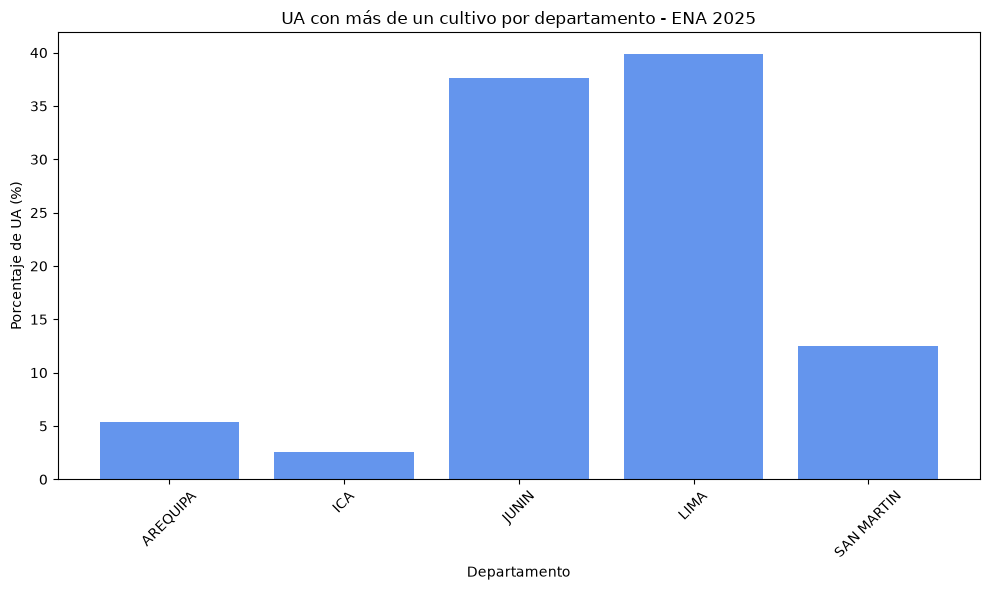

In [25]:
# Gráfico de barras

plt.figure(figsize=(10, 6))
plt.bar(
    tabla_07["NOMBREDD"], 
    tabla_07["porcentaje"], 
    color="cornflowerblue"
)

plt.title("UA con más de un cultivo por departamento - ENA 2025")
plt.xlabel("Departamento")
plt.ylabel("Porcentaje de UA (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## Gráfico 8. Principales cultivos según departamento

In [26]:
# Tabla estadística

cultivos_top = df_03_CAP200A_limp["P204_NOM"].value_counts().head(10).index
df_top = df_03_CAP200A_limp[df_03_CAP200A_limp["P204_NOM"].isin(cultivos_top)].copy()

tabla_08 = pd.crosstab(df_top["P204_NOM"], df_top["NOMBREDD"])
tabla_08

NOMBREDD,AREQUIPA,ICA,JUNIN,LIMA,SAN MARTIN
P204_NOM,,,,,
ALFALFA,9532,1010,961,2353,0
PASTO BRAQUIARIA,0,0,64,2,475
PASTO BRIZANTA,4,9,19,12,1024
PASTO DACTYLIS,109,0,202,358,0
PASTO ELEFANTE,0,0,18,92,129
PASTO KIKUYO,73,3,32,1194,0
PASTO KING GRASS,33,0,0,27,21
PASTO NATURAL MANEJADO,30,0,201,264,0
RYE GRASS,206,13,1247,457,0


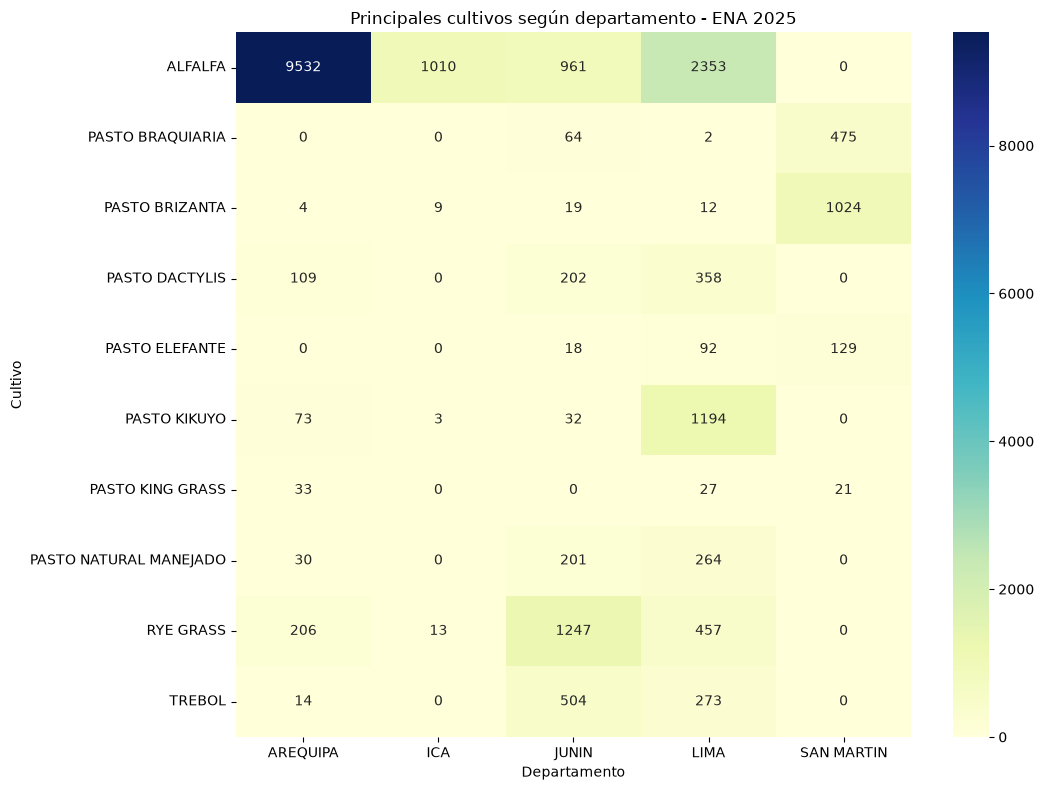

In [27]:
# Mapa de calor estadístico

plt.figure(figsize=(11, 8))
sns.heatmap(
    tabla_08, 
    annot=True, 
    fmt="d", 
    cmap="YlGnBu"
)

plt.title("Principales cultivos según departamento - ENA 2025")
plt.xlabel("Departamento")
plt.ylabel("Cultivo")
plt.tight_layout()
plt.show()

## Gráfico 9. Principales cultivos según región natural

In [28]:
# Tabla estadística

cultivos_top = df_03_CAP200A_limp["P204_NOM"].value_counts().head(10).index
df_top = df_03_CAP200A_limp[df_03_CAP200A_limp["P204_NOM"].isin(cultivos_top)].copy()

tabla_09 = pd.crosstab(df_top["P204_NOM"], df_top["REGION"])
tabla_09

REGION,1,2,3
P204_NOM,,,
ALFALFA,4642,9214,0
PASTO BRAQUIARIA,2,0,539
PASTO BRIZANTA,25,0,1043
PASTO DACTYLIS,3,666,0
PASTO ELEFANTE,92,3,144
PASTO KIKUYO,21,1281,0
PASTO KING GRASS,2,58,21
PASTO NATURAL MANEJADO,5,448,42
RYE GRASS,39,1884,0


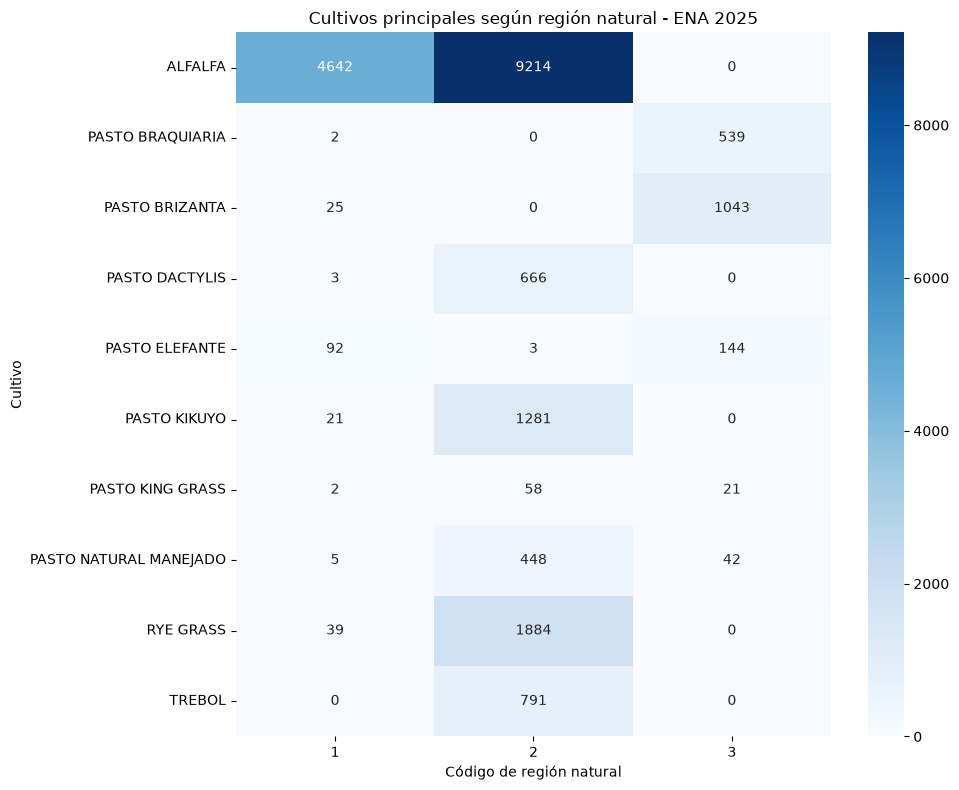

In [29]:
# Mapa de calor estadístico

plt.figure(figsize=(10, 8))
sns.heatmap(
    tabla_09,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Cultivos principales según región natural - ENA 2025")
plt.xlabel("Código de región natural")
plt.ylabel("Cultivo")
plt.tight_layout()

plt.show()

## Gráfico 10. Relación entre cantidad de registros y diversidad de cultivos por provincia

In [30]:
# Tabla estadística

tabla_10 = df_03_CAP200A_limp.groupby(["NOMBREDD", "NOMBREPV"]).agg(
    registros=("P204_COD", "size"),
    cultivos_distintos=("P204_COD", "nunique")
).reset_index()

tabla_10

,NOMBREDD,NOMBREPV,registros,cultivos_distintos
0,AREQUIPA,AREQUIPA,2281,4
1,AREQUIPA,CAMANA,68,1
2,AREQUIPA,CARAVELI,513,1
3,AREQUIPA,CASTILLA,1762,5
4,AREQUIPA,CAYLLOMA,2519,6
5,AREQUIPA,CONDESUYOS,1369,6
6,AREQUIPA,ISLAY,516,1
7,AREQUIPA,LA UNION,1013,5
8,ICA,CHINCHA,126,3
9,ICA,ICA,72,1


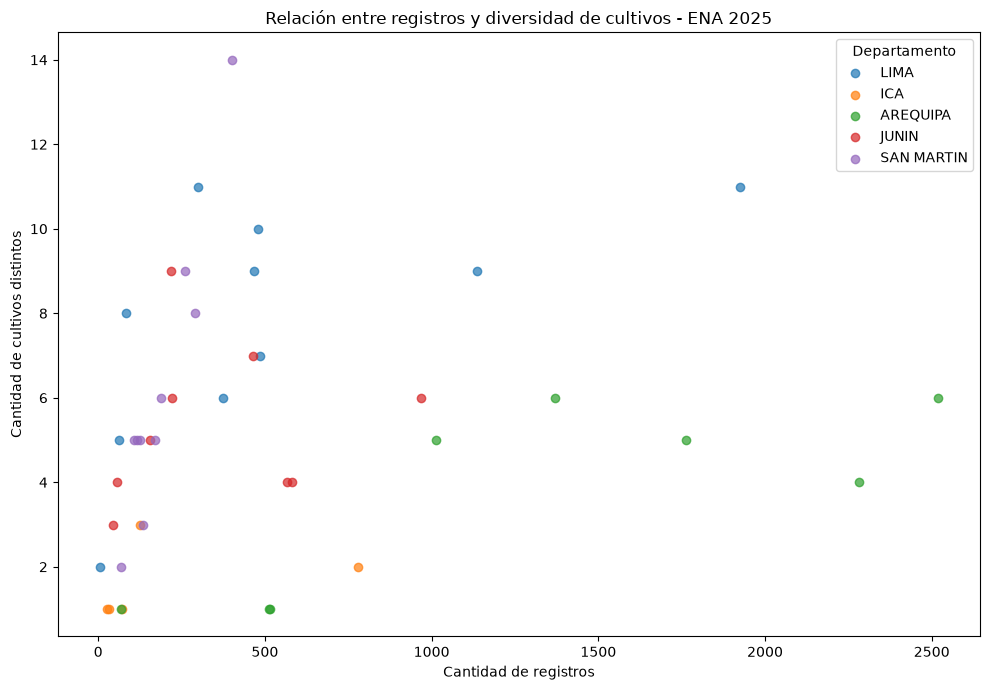

In [31]:
# Gráfico de dispersión

plt.figure(figsize=(10, 7))

for departamento in departamentos:
    datos = tabla_10[tabla_10["NOMBREDD"] == departamento]
    plt.scatter(datos["registros"], datos["cultivos_distintos"], label=departamento, alpha=0.7)

plt.title("Relación entre registros y diversidad de cultivos - ENA 2025")
plt.xlabel("Cantidad de registros")
plt.ylabel("Cantidad de cultivos distintos")
plt.legend(title="Departamento")
plt.tight_layout()
plt.show()